# Load Data and Generate Holdout Forecasts

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.data import load_cpu, build_targets, split_train_holdout
from cwfc.baselines import persistence_forecast, train_mean_forecast
from cwfc.metrics import mae, rmse, relative_improvement, subset_metrics

cpu = load_cpu("../challenge_data/vm_cpu_readings.csv.gz")
targets = build_targets(cpu)
train, holdout = split_train_holdout(targets)
template = holdout[["timestamp"]]

pred = pd.read_csv("../predictions.csv")
assert pred["timestamp"].tolist() == holdout["timestamp"].tolist()
print(len(train), len(holdout), len(pred))   # 110 24 24

110 24 24


# Evaluate Active VM Count

In [2]:
t = "active_vm_count"
print("MAE:", mae(holdout[t], pred[t]), "| RMSE:", rmse(holdout[t], pred[t]))

MAE: 0.0 | RMSE: 0.0


**What this shows:** The forecast for `active_vm_count` matches the holdout exactly (MAE 0, RMSE 0), as expected for a constant series.

# Compare CPU Forecasting Models

In [3]:
t = "aggregate_cpu_utilization"
actual = holdout[t].to_numpy()
final = pred[t].to_numpy()

peak_threshold = train[t].quantile(0.90)    # defined from the training window only
mask = actual >= peak_threshold

comparators = {
    "final (damped_persistence)": final,
    "last_value": persistence_forecast(train, template, t).to_numpy(),
    "train_mean": train_mean_forecast(train, template, t).to_numpy(),
}
ref_last, ref_mean = comparators["last_value"], comparators["train_mean"]

rows = []
for name, p in comparators.items():
    pk = subset_metrics(actual, p, mask)
    rows.append({
        "model": name,
        "MAE": mae(actual, p),
        "RMSE": rmse(actual, p),
        "vs_last_value": relative_improvement(actual, p, ref_last),
        "vs_train_mean": relative_improvement(actual, p, ref_mean),
        "peak_MAE": pk["mae"],
        "peak_points": pk["n"],
    })
holdout_table = pd.DataFrame(rows)
print("peak threshold:", round(peak_threshold, 3))
print(holdout_table.round(4))

peak threshold: 9.668
                        model     MAE    RMSE  vs_last_value  vs_train_mean  \
0  final (damped_persistence)  0.1533  0.1832        -0.0445         0.1218   
1                  last_value  0.1468  0.1848         0.0000         0.1593   
2                  train_mean  0.1746  0.2105        -0.1894         0.0000   

   peak_MAE  peak_points  
0       NaN            0  
1       NaN            0  
2       NaN            0  


**What this shows:** On the 24 holdout points the final model (`damped_persistence`) has MAE 0.1533 and RMSE 0.1832. It is 12.2% better than `train_mean` in MAE (about 13% in RMSE) and essentially tied with `last_value` (4.5% worse in MAE, about 1% better in RMSE). The holdout is a single, calm window, so the gap to `last_value` is within what one window can produce, and it is much smaller than the validation gap (damped was 23.7% better than `last_value` there). No holdout point reaches the training 90th percentile (9.668%), so peak error cannot be computed here and peak behavior rests on the validation results.

# Identify Largest Forecast Errors

   timestamp  step  actual   pred  abs_error
5      34500     6   9.046  9.391      0.345
1      33300     2   8.984  9.301      0.318
4      34200     5   9.078  9.380      0.302
2      33600     3   9.043  9.338      0.295
6      34800     7   9.164  9.399      0.235


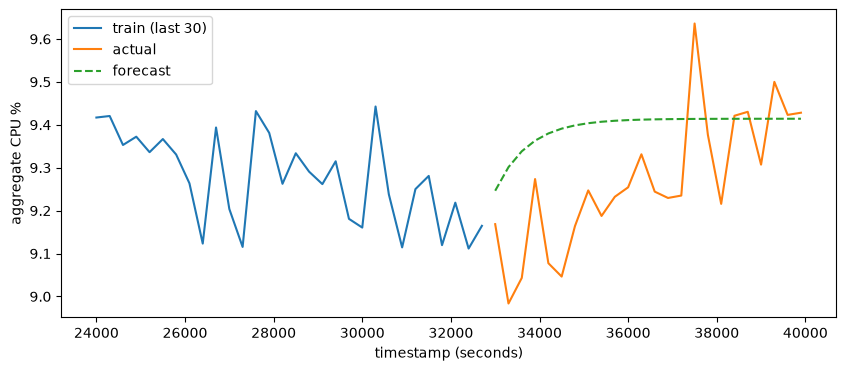

In [4]:
err = pd.DataFrame({
    "timestamp": holdout["timestamp"].to_numpy(),
    "step": range(1, len(holdout) + 1),
    "actual": actual,
    "pred": final,
})
err["abs_error"] = (err["actual"] - err["pred"]).abs()
print(err.sort_values("abs_error", ascending=False).head(5).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(train["timestamp"].tail(30), train[t].tail(30), label="train (last 30)")
ax.plot(holdout["timestamp"], actual, label="actual")
ax.plot(holdout["timestamp"], final, label="forecast", linestyle="--")
ax.set_xlabel("timestamp (seconds)")
ax.set_ylabel("aggregate CPU %")
ax.legend()
plt.show()

**What this shows:** The five largest errors (0.24 to 0.35 points) all fall in steps 2 to 7, the first 35 minutes, and in all of them the forecast is above the actual value (forecast 9.30 to 9.40 versus actual 8.98 to 9.16). The bias analysis below shows how this error changes over the two-hour horizon.

# Compare Relative Model Improvements

In [5]:
rows = []
for name, p in comparators.items():
    rows.append({
        "model": name,
        "MAE_gain_vs_last": relative_improvement(actual, p, ref_last),
        "MAE_gain_vs_mean": relative_improvement(actual, p, ref_mean),
        "RMSE_gain_vs_last": 1 - rmse(actual, p) / rmse(actual, ref_last),
        "RMSE_gain_vs_mean": 1 - rmse(actual, p) / rmse(actual, ref_mean),
    })
print(pd.DataFrame(rows).round(4))

                        model  MAE_gain_vs_last  MAE_gain_vs_mean  \
0  final (damped_persistence)           -0.0445            0.1218   
1                  last_value            0.0000            0.1593   
2                  train_mean           -0.1894            0.0000   

   RMSE_gain_vs_last  RMSE_gain_vs_mean  
0             0.0084             0.1293  
1             0.0000             0.1220  
2            -0.1390             0.0000  


**What this shows:** Relative to `last_value`, the final model is 4.5% worse in MAE and 0.8% better in RMSE; relative to `train_mean` it is 12.2% better in MAE and 12.9% better in RMSE. Because the MAE and RMSE comparisons against `last_value` point in opposite directions, the two are treated as tied.

# Analyze Forecast Bias Over Time

In [6]:
err["signed_error"] = err["pred"] - err["actual"]
print("mean signed error (pred - actual):", round(err["signed_error"].mean(), 4))
print("share of steps with forecast too high:", round((err["signed_error"] > 0).mean(), 2))

err["block"] = pd.cut(err["step"], [0, 6, 12, 18, 24],
                      labels=["1-6", "7-12", "13-18", "19-24"])
print(err.groupby("block", observed=True)[["abs_error", "signed_error"]].mean().round(3))

mean signed error (pred - actual): 0.1238
share of steps with forecast too high: 0.75
       abs_error  signed_error
block                         
1-6        0.238         0.238
7-12       0.171         0.171
13-18      0.165         0.091
19-24      0.040        -0.004


**What this shows:** The forecast was above the actual value in 75% of the steps (mean signed error +0.12 points), but the error is concentrated early: the mean signed error is +0.24 in steps 1 to 6, +0.17 in steps 7 to 12 and +0.09 in steps 13 to 18, and about 0 in steps 19 to 24, where forecast and actual nearly coincide (mean absolute error 0.04). The model is therefore not biased overall; it moved back toward the training mean (9.41%) faster than the actual load recovered. This matches the validation finding that the fitted decay forgets the recent level faster than the series does. The model was not changed after seeing this; a slower or better-calibrated return to the long-run level is noted as future work.

# Evaluate High-Load Performance

In [7]:
hi = actual >= np.quantile(actual, 0.75)    # top quarter of the holdout itself (n=6)
for name, p in comparators.items():
    print(name, subset_metrics(actual, p, hi))

final (damped_persistence) {'n': 6, 'mae': 0.05910150256137392, 'rmse': 0.09781618974528547}
last_value {'n': 6, 'mae': 0.3085108235022454, 'rmse': 0.3181732758496891}
train_mean {'n': 6, 'mae': 0.0589779789483836, 'rmse': 0.0976407048710971}


**Exploratory, not part of the main evidence:** The top quarter of the holdout points (6 points, with the cutoff taken from the holdout values themselves) is a relative high-load slice. On it the mean-reverting forecasts (`damped_persistence` MAE 0.059, `train_mean` 0.059) are about five times more accurate than `last_value` (0.309). With only 6 points and a cutoff set from the test values, this is only a descriptive observation. It points the opposite way from the validation peaks, where `last_value` had the lowest error, so the best method depends on the situation: inside a hump, recent values win; when load returns toward its average, mean-reverting forecasts win.